# Итоговые графики: retrieval-головы Qwen3-8B на простой и усложнённых задачах

Пять утверждений, на каждое — одно предложение результата; три усложнения (оси A, B, N) сведены на один рисунок. Подробности и все остальные разрезы — в `paper_task.ipynb`, `hard_A.ipynb`, `hard_B.ipynb`, `hard_N.ipynb`.

**Итог одним предложением.** Головы, найденные по метрике копирования на простой задаче, остаются теми же и на усложнённых задачах, а их отключение везде бьёт по фактичности ответа: перефраз вопроса и близнецы немного снижают их скор копирования (0.68 → 0.61), шум не меняет ничего, отключение 60 лучших голов оставляет на сложных иглах от 29% до 55% верных ответов (на исходной игле 85%, при 100 головах — 2%) против 99–100% при отключении 60 случайных.

Рисунки сохраняются в `vizual/figures/summary_*.png` шириной 17.3 см.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))   # корень репозитория: ноутбук лежит в vizual/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from vizual import data, hard, paraphrase, plots, style

WIDTH = 17.3 / 2.54       # ширина рисунка в дюймах: ячейка постера 17.3 см
SAVE = True               # сохранять рисунки в vizual/figures/
HARD = "results/new/qwen3_hard_fast"
SIMPLE_KEY = [["sandwich"], ["Dolores Park"]]   # два ключевых факта исходной иглы, по образцу answer_key сложных задач

# цвета постера: один фиолетовый тон от светлого к тёмному и серый для точки отсчёта
VIOLET = ["#f1ecfe", "#e2d8fd", "#cfbffb", "#b9a1f8", "#a183f4", "#8b66ee", "#7748e3", "#6433cc", "#5226ac", "#411d8a", "#2f1466"]
GREY = "#6b6a66"
style.RAMP[:] = VIOLET    # градиент столбиков, стопок и линий в этом ноутбуке
style.use(font=8.5, dpi=170, line=1.6, marker=4.5,
          colors={"top": VIOLET[7], "random": VIOLET[3], "random_groups": GREY, "none": GREY, "accent": VIOLET[6], "second": VIOLET[3], "muted": "#d9d7d0"})
t = style.THEME
MASKS = {"none": "без маски", "random60": "60 случайных", "top40": "40 лучших", "top60": "60 лучших"}
MASK_COLORS = {"none": GREY, "random60": VIOLET[2], "top40": VIOLET[5], "top60": VIOLET[9]}

def figure(rows, columns, height, **kwargs):
    return plt.subplots(rows, columns, figsize=(WIDTH, height), **kwargs)

def show(fig, name):
    if SAVE:
        plots.save(fig, f"summary_{name}", formats=("png",))
    plt.show()

def below(ax, columns=2, **kwargs):
    # легенда под графиком: над ним ничего не должно быть
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.24), ncol=columns, **kwargs)

In [2]:
from rh.metrics import fact_class

# исходная задача: игла про Сан-Франциско
simple = paraphrase.annotate(data.load_sweep("results/new/qwen3_mask/*"))
simple["correct"] = [fact_class(r, {"answer_key": SIMPLE_KEY})["answer_class"] == "correct" for r in simple["response"]]

# сложные задачи; уровень A0 — общая точка отсчёта
axis_a = hard.load(f"{HARD}/A/*")
a0 = axis_a[axis_a["level"] == "A0"]
axis_b = pd.concat([a0, hard.load(f"{HARD}/B/*")], ignore_index=True)
axis_n = pd.concat([a0, hard.load(f"{HARD}/N/*")], ignore_index=True)

# головы: рейтинг детекции на простой задаче и метрики голов на уровнях сложных задач (прогоны без маски, верные ответы)
detect = data.Heads("results/new/qwen3_detect")
reference = detect.score("copy_recall")
order = np.argsort(-reference.ravel(), kind="stable")
best = order[:20]

def head_levels(df, folder):
    heads = data.Heads(f"{HARD}/{folder}/none", samples=df[df["run"] == "none"], ok="correct")
    common = hard.common_cells(heads.samples)
    return lambda metric: {level: score.ravel()[best].mean() for level, score in hard.level_scores(heads, metric, where=common).items()}, heads, common

heads_a, raw_a, common_a = head_levels(axis_a, "A")
heads_b, raw_b, common_b = head_levels(axis_b, "B")
heads_n, raw_n, common_n = head_levels(axis_n, "N")
print("ответов:", {"исходная": len(simple), "A": len(axis_a), "B": len(axis_b), "N": len(axis_n)})

ответов: {'исходная': 3800, 'A': 3168, 'B': 3955, 'N': 3960}


## Задачи и уровни

**Исходная задача (статья).** В длинный текст вставлено одно предложение-игла, модель спрашивают о нём дословным вопросом. Игла: «The best thing to do in San Francisco is eat a sandwich and sit in Dolores Park on a sunny day», вопрос: «What is the best thing to do in San Francisco?». Сетка: 20 длин контекста от 1k до 30k токенов × 10 глубин иглы.

**Усложнённые задачи.** Три другие иглы с выдуманными ответами (Лиссабон, Каир, Осло), три оси усложнения. На каждой оси меняется что-то одно, а уровень **A0** — общая точка отсчёта: та же игла, дословный вопрос, никаких вставок. Сетка: 11 длин × 6 глубин × 3 иглы.

Пример иглы: «Every visitor to the Lisbon Tram Museum is asked to ring the brass bell at the entrance and sign the guest book with a green pen».

| Уровень | Что сделано | Пример | Что проверяет |
|---|---|---|---|
| **A0** | дословный вопрос, вставок нет | What is every visitor to the Lisbon Tram Museum asked to do? | точка отсчёта |
| | | **Ось A — меняется вопрос** | |
| **A1** | вопрос перефразирован, ключ (город и место) сохранён | What are guests of the Lisbon Tram Museum requested to do when they arrive? | поиск по смыслу, а не по совпадению слов |
| **A2** | вопрос дословный, ключ заменён описанием | What is every visitor to the tram museum of the Portuguese capital asked to do? | поиск без названного ключа; нужно знать, что город — столица |
| **A3** | перефраз и замена ключа вместе | What are guests of the tram museum in Portugal's capital requested to do when they arrive? | оба усложнения сразу |
| | | **Ось B — в текст добавлены близнецы:** предложения того же шаблона про другой город с другими фактами | |
| **B1** | один близнец далеко от иглы (на противоположной глубине) | Every visitor to the Porto Tram Museum is asked to pull the iron lever at the gate and stamp the entry card with a red seal. | мешает ли само существование похожей записи |
| **B2** | три близнеца в случайных местах | + Madrid Railway Museum, Vienna Transport Museum | число конкурентов |
| **B3** | три близнеца рядом с иглой (в пределах 200 токенов) | те же три записи | близость конкурентов |
| **B4** | одна запись с тем же ключом, но о другом, рядом с иглой | Every employee of the Lisbon Tram Museum is asked to polish the silver rails at dawn and lock the depot with a heavy chain. | различает ли модель записи про одно и то же место |
| | | **Ось N — в текст добавлен шум:** яркие факты, не связанные с вопросом и не похожие на иглу | |
| **N1** | один яркий факт далеко от иглы | BREAKING NEWS: a giant meteorite has just crashed into the Pacific Ocean, and scientists warn that a huge tsunami may hit the coast within hours. | мешает ли заметный текст сам по себе |
| **N2** | тот же факт рядом с иглой | тот же | близость шума |
| **N3** | три ярких факта рядом | + извержение вулкана, Луна удаляется от Земли | количество шума |
| **N4** | яркий факт про тот же город, рядом | BREAKING NEWS: a burning meteorite has fallen on the outskirts of Lisbon, and thousands of people saw a blinding glare in the night sky. | шум, содержащий ключ вопроса |

Длина вставок вычитается из текста, поэтому промпт на каждом уровне той же длины, что на A0.

**Маски.** Головы упорядочены по метрике авторов (скор копирования) на исходной задаче и на усложнённых задачах не переопределяются. Отключаются 40 или 60 лучших голов (на исходной задаче — от 20 до 120) либо 60 случайных.

**Как проверяется ответ.** На исходной задаче — ROUGE-2 и ROUGE-1 recall с эталоном. На усложнённых — по фактам: ответ верен, если названы оба ключевых факта иглы (`brass bell` и `guest book`) и нет фактов вставок.

## 1. Исходная задача: эксперимент воспроизводится, модель теряет ответ, а не пересказывает его

**Результат.** На Qwen3-8B отключение лучших по метрике авторов голов обрушивает поиск иглы (при 120 головах ROUGE-2 100 → 8, ROUGE-1 100 → 41), а отключение случайных — нет (ROUGE-2 не ниже 98.5), как в статье; при этом ответ не пересказывается, а обрезается и затем теряется: перефразированных полных ответов 6 из 3800.

ROUGE-2 — основная метрика рисунка: на этой задаче она точнее всего согласуется с разбором ответа по частям. ROUGE-1 (метрика статьи) показан пунктиром для сравнения: он завышает качество, потому что засчитывает отдельные слова эталона в ответах не по игле.

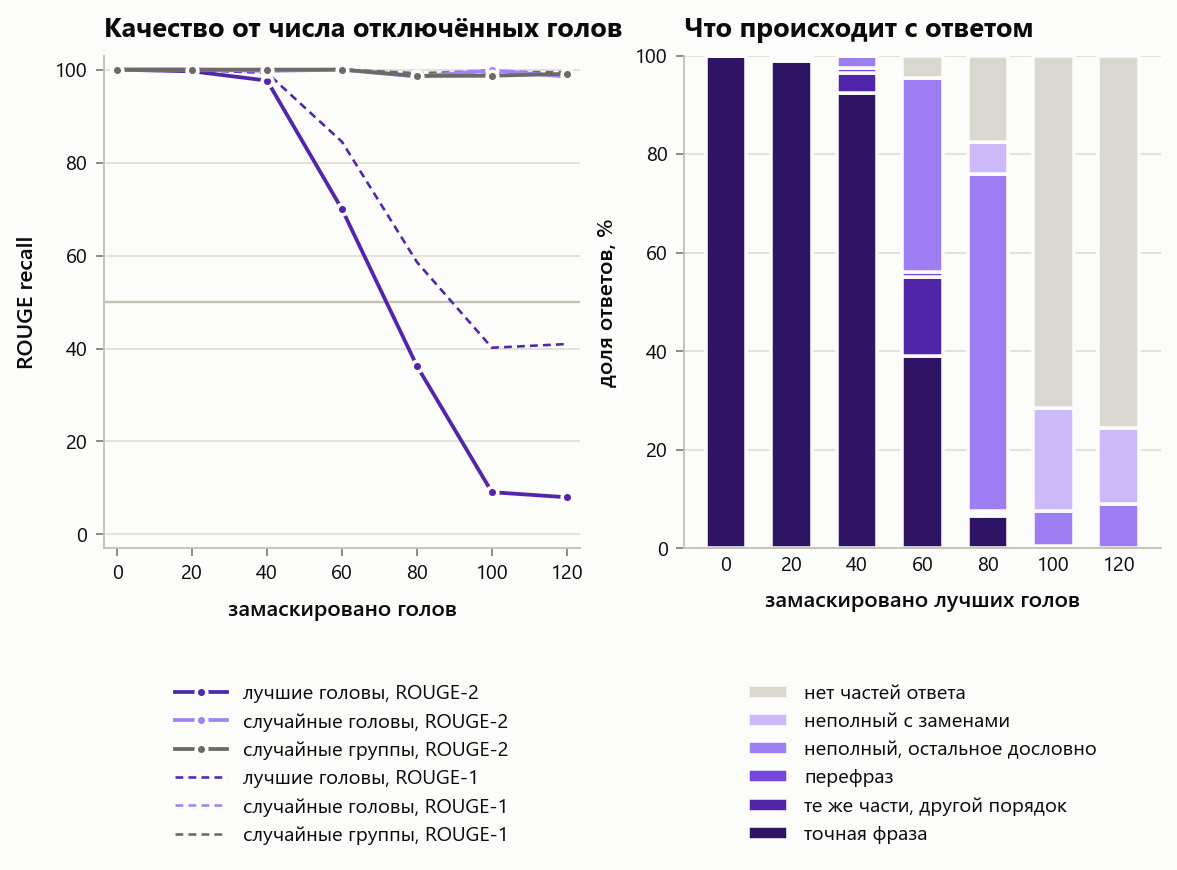

перефразированных полных ответов: 6 из 3800; голов выше порога 0.1: 62 из 1152 (5.4%), со скором 0: 57.9%


heads,0,20,40,60,80,100,120
rouge1_recall,100.0,99.9,99.3,84.5,58.6,40.2,41.0
rouge2_recall,100.0,99.6,97.6,70.0,36.2,9.1,8.0


heads,20,40,60,80,100,120
rouge1_recall,100.0,99.8,100.0,99.1,99.9,99.0
rouge2_recall,100.0,99.7,100.0,98.5,99.8,98.5


heads,20,40,60,80,100,120
rouge1_recall,100.0,100.0,100.0,99.2,99.5,99.5
rouge2_recall,100.0,100.0,100.0,98.6,98.7,99.1


верные по двум ключевым фактам, %: маска лучших голов


heads,0,20,40,60,80,100,120
верно,100.0,100.0,100.0,84.5,31.0,1.5,2.5


In [3]:
SHORT = {"exact": "точная фраза", "reordered": "те же части, другой порядок", "reworded": "перефраз", "cut": "неполный, остальное дословно",
         "cut_reworded": "неполный с заменами", "none": "нет частей ответа"}

fig, axes = figure(1, 2, 5.0)
ax = axes[0]
kinds = {"top": ("лучшие головы", VIOLET[8]), "random": ("случайные головы", VIOLET[4]), "random_groups": ("случайные группы", GREY)}
stats = simple.groupby(["mask", "heads"])[["rouge1_recall", "rouge2_recall"]].mean()
most = int(simple["heads"].max())
for metric, name, look in (("rouge2_recall", "ROUGE-2", dict(marker="o")), ("rouge1_recall", "ROUGE-1", dict(linestyle=(0, (3, 2)), linewidth=1.1))):
    for kind, (label, color) in kinds.items():
        line = pd.concat([stats.loc[["none"]], stats.loc[[kind]]]).reset_index().sort_values("heads")
        ax.plot(line["heads"], line[metric], color=color, label=f"{label}, {name}", zorder=3 if metric == "rouge2_recall" else 2, **look)
ax.axhline(50, color=t.axis, linewidth=1, zorder=1)
plots.round_axis(ax, "x", 0, most, 20)
ax.set_xlim(-most * 0.03, most * 1.03)
ax.set_ylim(-3, 103)
plots.round_axis(ax, "y", 0, 100, 20)
ax.set_xlabel("замаскировано голов")
ax.set_ylabel("ROUGE recall")
plots.titles(ax, "Качество от числа отключённых голов")
below(ax, 1, handlelength=2.6)
plots.shares(simple, "structure", paraphrase.STRUCTURES, SHORT, "top", ax=axes[1], title="Что происходит с ответом")
axes[1].set_xlabel("замаскировано лучших голов")
below(axes[1], 1, reverse=True)
show(fig, "1_paper_task")

counts = simple["structure"].value_counts()
score = reference.ravel()
print(f"перефразированных полных ответов: {counts.get('reworded', 0)} из {len(simple)}; "
      f"голов выше порога 0.1: {(score > 0.1).sum()} из {score.size} ({(score > 0.1).mean():.1%}), со скором 0: {(score == 0).mean():.1%}")
display(simple[simple["mask"].isin(["none", "top"])].groupby("heads")[["rouge1_recall", "rouge2_recall"]].mean().round(1).T)
display(simple[simple["mask"] == "random"].groupby("heads")[["rouge1_recall", "rouge2_recall"]].mean().round(1).T)
display(simple[simple["mask"] == "random_groups"].groupby("heads")[["rouge1_recall", "rouge2_recall"]].mean().round(1).T)
print("верные по двум ключевым фактам, %: маска лучших голов")
display((simple[simple["mask"].isin(["none", "top"])].groupby("heads")["correct"].mean() * 100).round(1).to_frame("верно").T)

## 2–4. Усложнения: перефраз вопроса (A), близнецы (B), шум (N)

Два рисунка. На первом — метрика авторов без маски по уровням каждой оси. На втором — ответы: строка — ось и мера, столбец — маска, внутри панели на каждый уровень стопка классов, как в ноутбуках осей. Легенды справа. Шесть классов каждой градации идут тремя парами от лучшей к худшей: у каждой пары свой цвет по градиенту оси (A: тёмно-фиолетовый → пурпурный → розовый; B: тёмно-бирюзовый → зелёный → жёлто-зелёный; N: красно-коричневый → оранжевый → жёлтый), второй класс в паре заштрихован. В легендах те же три ступени показаны серым, потому что схема одна для всех осей. Первый уровень у всех общий: дословный вопрос без вставок (A0).

- **Фактологическая точность** (строки «факты») — класс ответа по ключевым фактам: верно, смешано, частично, путаница, шум, иное.
- **Точность по фразам** (строки «фразы») — как записан ответ относительно эталонной фразы: точная фраза, те же части в другом порядке, перефраз, неполный ответ, неполный с заменами, нет частей ответа.

| Ось | Уровень 1 | Уровень 2 | Уровень 3 | Уровень 4 |
|---|---|---|---|---|
| **A**, перефраз вопроса | перефраз | ключ заменён описанием | оба изменения | — |
| **B**, близнецы | один далеко | три случайно | три рядом | запись с тем же ключом |
| **N**, шум | яркий факт далеко | рядом | три рядом | с ключом вопроса |

**Результат 2 (ось A).** Когда вопрос перестаёт повторять слова иглы, скор копирования 20 лучших голов (метрика авторов) снижается с 0.68 до 0.61, а под маской сначала меняются слова и только потом факты: при 40 головах точных фраз почти нет (80% → 1% по всем уровням оси), но 76% ответов остаются верными, при 60 головах верных 30%.

**Результат 3 (ось B).** Записи того же шаблона с другими фактами снижают скор копирования с 0.68 до 0.61–0.65, и 0.05–0.08 той же метрики приходится на токены, списанные из близнецов, но при отключённых головах ответ с близнецами ближе к игле: при 60 головах точных фраз 0% без вставок и до 32% с близнецами, верных по фактам — 30% и до 70%.

**Результат 4 (ось N).** Яркие факты, не связанные с вопросом, не меняют ничего: скор копирования остаётся 0.68–0.69, из шума головы не копируют, доля верных ответов отличается от уровня без вставок не более чем на 7 п.п. при любой маске, и шум ни разу не попал в ответ.

Оговорки. Снижение скора на оси A — следствие формулировки ответа: на дословных ответах он одинаков на всех уровнях (0.67–0.68). На оси B при 40 головах близнецы, наоборот, снижают долю верных по фактам (71% → 56–59% на уровнях 1–3); выигрыш по фактам есть только при 60 головах.

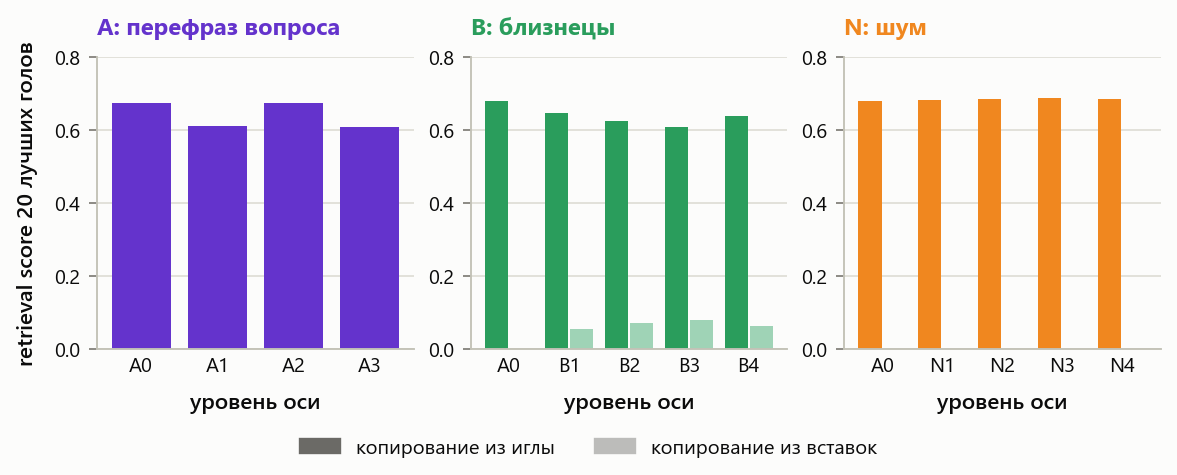

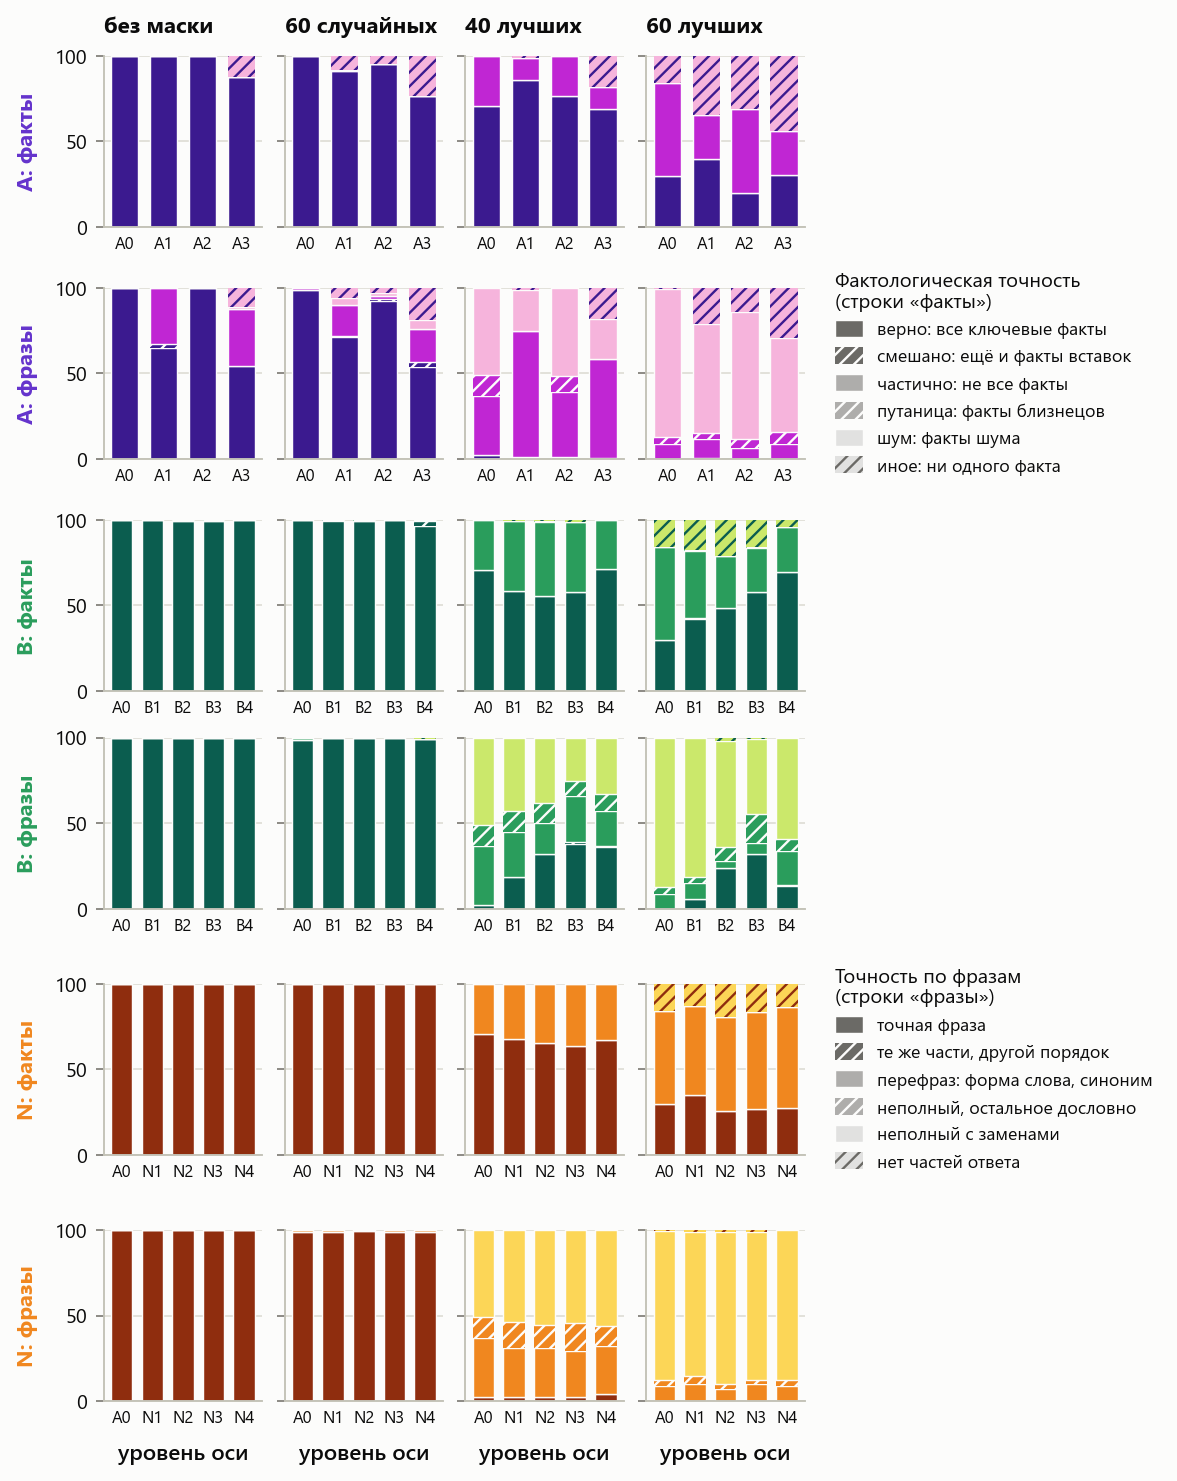

A0       1  \
ось величина                                                             
A   копирование из иглы                                   0.68    0.61   
B   копирование из иглы                                   0.68    0.65   
    копирование из вставок                                0.00    0.05   
N   копирование из иглы                                   0.68    0.68   
    копирование из вставок                                0.00    0.00   
A   факты: верно: все ключевые факты, без маски         100.00  100.00   
    факты: иное: ни одного факта, без маски               0.00    0.00   
    факты: верно: все ключевые факты, 60 случайных      100.00   90.91   
    факты: частично: не все факты, 60 случайных           0.00    0.51   
    факты: иное: ни одного факта, 60 случайных            0.00    8.59   
    факты: верно: все ключевые факты, 40 лучших          70.71   85.86   
    факты: частично: не все факты, 40 лучших             29.29   12.63   
    факты: иное: ни одного факта, 40 лучших               0.00    1.52   
    факты: верно: все ключевые факты, 60 лучших          29.80   39.90   
    факты: частично: не все факты, 60 лучших             54.55   25.76   
    факты: иное: ни одного факта, 60 лучших              15.66   34.34   
    фразы: точная фраза, без маски                      100.00   64.65   
    фразы: те же части, другой порядок, без маски         0.00    2.53   
    фразы: перефраз: форма слова, синоним, без маски      0.00   32.83   
    фразы: неполный с заменами, без маски                 0.00    0.00   
    фразы: нет частей ответа, без маски                   0.00    0.00   
    фразы: точная фраза, 60 случайных                    98.48   71.21   
    фразы: те же части, другой порядок, 60 случайных      0.00    0.51   
    фразы: перефраз: форма слова, синоним, 60 случа...    1.52   18.18   
    фразы: неполный с заменами, 60 случайных              0.00    4.04   
    фразы: нет частей ответа, 60 случайных                0.00    6.06   
    фразы: точная фраза, 40 лучших                        2.53    0.51   
    фразы: те же части, другой порядок, 40 лучших         0.00    0.51   
    фразы: перефраз: форма слова, синоним, 40 лучших     34.34   73.74   
    фразы: неполный, остальное дословно, 40 лучших       12.12    0.00   
    фразы: неполный с заменами, 40 лучших                51.01   23.74   
    фразы: нет частей ответа, 40 лучших                   0.00    1.52   
    фразы: точная фраза, 60 лучших                        0.00    0.51   
    фразы: перефраз: форма слова, синоним, 60 лучших      8.59   11.11   
    фразы: неполный, остальное дословно, 60 лучших        4.04    3.54   
    фразы: неполный с заменами, 60 лучших                86.87   63.64   
    фразы: нет частей ответа, 60 лучших                   0.51   21.21   
B   факты: верно: все ключевые факты, без маски         100.00  100.00   
    факты: путаница: факты близнецов, без маски           0.00    0.00   
    факты: верно: все ключевые факты, 60 случайных      100.00   98.99   
    факты: смешано: ещё и факты вставок, 60 случайных     0.00    1.01   
    факты: путаница: факты близнецов, 60 случайных        0.00    0.00   
    факты: верно: все ключевые факты, 40 лучших          70.71   58.59   
    факты: частично: не все факты, 40 лучших             29.29   40.91   
    факты: путаница: факты близнецов, 40 лучших           0.00    0.00   
    факты: иное: ни одного факта, 40 лучших               0.00    0.51   
    факты: верно: все ключевые факты, 60 лучших          29.80   41.92   
    факты: смешано: ещё и факты вставок, 60 лучших        0.00    0.51   
    факты: частично: не все факты, 60 лучших             54.55   39.39   
    факты: путаница: факты близнецов, 60 лучших           0.00    0.51   
    факты: иное: ни одного факта, 60 лучших              15.66   17.68   
    фразы: точная фраза, без маски                      100.00  100.00   
    фразы: неполный, остальное дословно, без маски        0.00  

,"точная фраза, %","верно по фактам, %"
run,,
без маски,79.8,96.8
40 лучших,1.1,75.6
60 лучших,0.1,30.1


ось A, скор копирования только на дословных ответах: {'A0': 0.678, 'A1': 0.675, 'A2': 0.674, 'A3': 0.665}
ось N: ответов с фактами шума: 0 из 3168 ; со словами шума: 0


In [4]:
from matplotlib.colors import to_hex, to_rgb

from matplotlib.patches import Patch

AXES = {"A": ("перефраз вопроса", VIOLET[7], axis_a, heads_a), "B": ("близнецы", "#2a9d5c", axis_b, heads_b), "N": ("шум", "#f0871f", axis_n, heads_n)}
steps = lambda df: sorted(df["level"].unique())          # уровни оси по порядку, первый — A0
tint = lambda color, fade: to_hex([c + (1 - c) * fade for c in to_rgb(color)])    # цвет оси, осветлённый на долю fade
REST = "#d9d7d0"                                          # последний класс: ни фактов, ни частей ответа

# классы по фактам и структуры по фразам — те же, что в ноутбуках осей, от лучшего к худшему
FACT_CLASSES = {"correct": "верно: все ключевые факты", "mixed": "смешано: ещё и факты вставок", "partial": "частично: не все факты",
                "confusion": "путаница: факты близнецов", "noise": "шум: факты шума", "other": "иное: ни одного факта"}
PHRASES = {"exact": "точная фраза", "reordered": "те же части, другой порядок", "reworded": "перефраз: форма слова, синоним",
           "cut": "неполный, остальное дословно", "cut_reworded": "неполный с заменами", "none": "нет частей ответа"}
# три пары классов — три цвета по градиенту оси, от тёмного (лучшая пара) к светлому; у каждой оси свой градиент
PAIR_COLORS = {"A": ["#3b1a8f", "#c026d3", "#f6b4dc"],     # тёмно-фиолетовый → пурпурный → розовый
               "B": ["#0b5d4f", "#2a9d5c", "#cbe86b"],     # тёмно-бирюзовый → зелёный → жёлто-зелёный
               "N": ["#8f2d0e", "#f0871f", "#fcd657"],     # красно-коричневый → оранжевый → жёлтый
               None: [tint(GREY, 0.0), tint(GREY, 0.45), tint(GREY, 0.80)]}   # общая легенда: те же три ступени серым

def looks(colors, n):
    # вид каждого класса градации: классы идут парами одного цвета, второй в паре — со штриховкой
    out = []
    for i in range(n):
        step = min(i // 2, len(colors) - 1)
        if i % 2 == 0:
            out.append(dict(facecolor=colors[step], edgecolor=t.surface, linewidth=0.6))
        else:
            # штрихи цветом фона на тёмных ступенях и тёмным цветом градиента на светлой, иначе их не видно
            out.append(dict(facecolor=colors[step], hatch="////", edgecolor=t.surface if step < len(colors) - 1 else colors[0], linewidth=0))
    return out

def gradation(ax, part, column, order, colors, levels):
    # стопка долей классов на каждый уровень
    share = (part.groupby("level")[column].value_counts(normalize=True).unstack(fill_value=0) * 100).reindex(index=levels, columns=list(order), fill_value=0)
    bottom = np.zeros(len(levels))
    for name, look in zip(order, looks(colors, len(order))):
        ax.bar(np.arange(len(levels)), share[name], bottom=bottom, width=0.7, **look)
        bottom += share[name].to_numpy()
    ax.set_xticks(np.arange(len(levels)), levels)
    ax.tick_params(axis="x", length=0, labelsize=t.font - 1.5)
    ax.set_ylim(0, 100)
    plots.round_axis(ax, "y", 0, 100, 50)

# --- метрика авторов без маски: копирование из иглы и из вставок, по уровням каждой оси
fig, axes = figure(1, 3, 2.7)
tables = {}
for ax, (name, (label, color, df, heads_of)) in zip(axes, AXES.items()):
    levels = steps(df)
    heads = pd.DataFrame({"из иглы": pd.Series(heads_of("copy_count"))}).reindex(levels)
    if name != "A":
        heads["из вставок"] = pd.Series(heads_of("copy_competing")).reindex(levels)
    width = 0.84 / len(heads.columns)
    for i, (column, shade) in enumerate(zip(heads.columns, [color, tint(color, 0.55)])):
        ax.bar(np.arange(len(levels)) + (i - (len(heads.columns) - 1) / 2) * width, heads[column], width=width * 0.92, color=shade)
        tables[(name, f"копирование {column}")] = heads[column].set_axis(range(len(levels)))
    ax.set_xticks(np.arange(len(levels)), levels)
    ax.tick_params(axis="x", length=0)
    ax.set_ylim(0, 0.8)
    plots.round_axis(ax, "y", 0, 0.8, 0.2)
    ax.set_xlabel("уровень оси")
    ax.set_ylabel("retrieval score 20 лучших голов" if ax is axes[0] else "")
    ax.set_title(f"{name}: {label}", loc="left", color=color, fontsize=t.font + 1.5)
fig.legend(handles=[Patch(color=tint(GREY, 0.0), label="копирование из иглы"), Patch(color=tint(GREY, 0.55), label="копирование из вставок")],
           loc="outside lower center", ncol=2)
show(fig, "2a_axes_metric")

# --- ответы: градация классов по уровням под каждой маской; строка — ось и мера, столбец — маска, легенды справа
worded = {name: paraphrase.annotate(df) for name, (_, _, df, _) in AXES.items()}
measures = (("answer_class", FACT_CLASSES, "факты"), ("structure", PHRASES, "фразы"))
fig = plt.figure(figsize=(WIDTH, 8.6))
grid = fig.add_gridspec(len(AXES) * len(measures), len(MASKS) + 1, width_ratios=[1] * len(MASKS) + [1.55])
for a, (name, (label, color, _, _)) in enumerate(AXES.items()):
    df = worded[name]
    levels = steps(df)
    for m, (column, order, short) in enumerate(measures):
        row = a * len(measures) + m
        for c, run in enumerate(MASKS):
            ax = fig.add_subplot(grid[row, c])
            gradation(ax, df[df["run"] == run], column, order, PAIR_COLORS[name], levels)
            if row == 0:
                ax.set_title(MASKS[run], loc="left", fontsize=t.font + 1)
            if c == 0:
                ax.set_ylabel(f"{name}: {short}", color=color, fontweight="bold")
            else:
                ax.set_yticklabels([])
            if row == len(AXES) * len(measures) - 1:
                ax.set_xlabel("уровень оси")
            share = df[df["run"] == run].groupby("level")[column].value_counts(normalize=True).unstack(fill_value=0) * 100
            for kind in order:
                if kind in share:
                    tables[(name, f"{short}: {order[kind]}, {MASKS[run]}")] = share[kind].reindex(levels).set_axis(range(len(levels)))

# легенды справа: градация одна для всех осей, поэтому показана серым; цвет строки — ось
for rows, (column, order, short), title in ((slice(0, 3), measures[0], "Фактологическая точность\n(строки «факты»)"),
                                            (slice(3, 6), measures[1], "Точность по фразам\n(строки «фразы»)")):
    side = fig.add_subplot(grid[rows, -1])
    side.axis("off")
    side.legend(handles=[Patch(label=name, **look) for name, look in zip(order.values(), looks(PAIR_COLORS[None], len(order)))],
                title=title, loc="center left", bbox_to_anchor=(0.0, 0.5), alignment="left", handlelength=1.6, handleheight=1.1, fontsize=t.font - 1)
show(fig, "2_axes_ABN")

table = pd.DataFrame(tables).T.rename(columns={0: "A0"})
table.index.names = ["ось", "величина"]
pd.set_option("display.max_rows", 200)
display(table.round(2))

# к результату 2: на оси A точные фразы и верные ответы по всем уровням оси, и скор только на дословных ответах
pooled = axis_a[axis_a["run"].isin(["none", "top40", "top60"])].groupby("run")[["exact", "correct"]].mean() * 100
display(pooled.round(1).rename(index=MASKS, columns={"exact": "точная фраза, %", "correct": "верно по фактам, %"}))
exact_only = hard.level_scores(raw_a, "copy_recall", where=raw_a.samples["exact"].to_numpy())
print("ось A, скор копирования только на дословных ответах:", {level: round(float(v.ravel()[best].mean()), 3) for level, v in exact_only.items()})
# к результату 4: шум в ответах
noisy = axis_n[axis_n["level"] != "A0"]
print("ось N: ответов с фактами шума:", int(noisy["answer_class"].isin(["noise", "mixed"]).sum()), "из", len(noisy),
      "; со словами шума:", int(hard.twin_words(noisy, "noise_facts").sum()))

## 5. Маскирование: роль голов сохраняется на всех задачах

Каждый столбик усложнённой оси — среднее по всем её уровням (A1–A3, B1–B4, N1–N4) и по трём иглам; A0 показан отдельно как точка отсчёта. Значения по отдельным уровням — на рисунке трёх осей выше.

Две меры правильности, оттенок — маска:

- **фактологическая точность** (фиолетовый) — проверка по ключам: в ответе названы ключевые факты иглы (`answer_key`: `brass bell` и `guest book`) и нет фактов вставок;
- **точность по фразам** (бирюзовый) — проверка по частям эталонной фразы: в ответе сохранены все её части (`ring the brass bell`, `at the entrance`, `sign the guest book`, `with a green pen`) — дословно, другой формой слова или синонимом, в любом порядке. Это разбор формулировок из подробных ноутбуков; ответ с потерянной деталью («ring a bell» без `brass`) или без одной из частей сюда не входит.

Вторая мера строже первой: она требует всего ответа, а не двух ключевых фактов, поэтому её столбики ниже. Сходство по эмбеддингам или другой моделью здесь не считалось.

**Результат.** На всех задачах отключение лучших по простой задаче голов резко снижает фактичность ответа, а отключение того же числа случайных голов её почти не трогает: при 60 лучших головах верных ответов на сложных иглах остаётся от 29% до 55%, при 60 случайных — 99–100% (на перефразированном вопросе 88% из-за одной иглы); исходная игла устойчивее (85% при 60 головах), но и она теряет факты при дальнейшем отключении: 31% при 80 головах и 2% при 100. По фразам картина та же, но резче: полный ответ под маской 60 лучших голов сохраняется в 9–29% случаев на сложных иглах и в 56% на исходной.

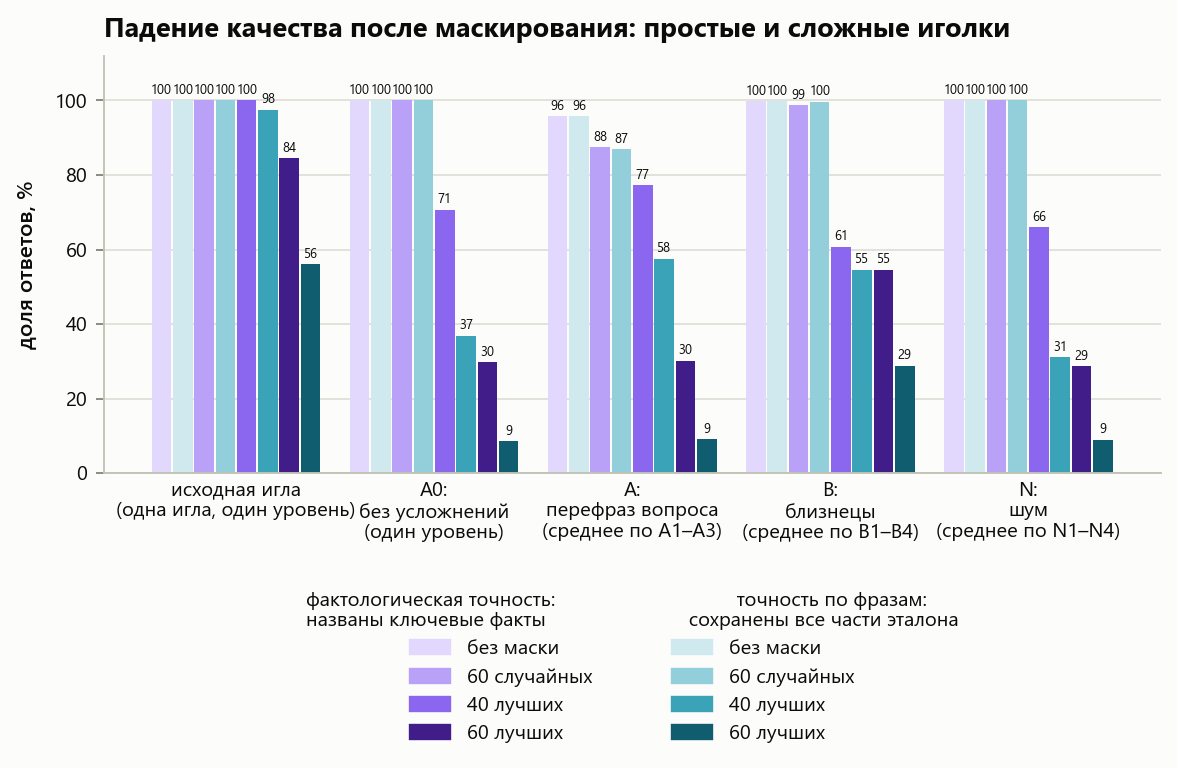

фактологическая точность (названы ключевые факты), %


run,none,random60,top40,top60
исходная игла,100.0,100.0,100.0,84.5
A0: без усложнений,100.0,100.0,70.7,29.8
A: перефраз вопроса,95.8,87.5,77.3,30.1
B: близнецы,99.7,98.7,60.7,54.5
N: шум,100.0,100.0,66.0,28.7


точность по фразам (сохранены все части эталона: дословно, формой слова или синонимом), %


run,none,random60,top40,top60
исходная игла,100.0,100.0,97.5,56.0
A0: без усложнений,100.0,100.0,36.9,8.6
A: перефраз вопроса,95.8,86.9,57.6,9.1
B: близнецы,99.7,99.6,54.5,28.8
N: шум,100.0,100.0,31.1,9.0


In [5]:
FULL = ["exact", "reordered", "reworded"]   # структуры ответа, в которых сохранены все части эталона
whole = lambda df: (df if "structure" in df else paraphrase.annotate(df)).assign(whole=lambda d: d["structure"].isin(FULL))
tasks = {"исходная игла": whole(simple),
         "A0: без усложнений": whole(a0),
         "A: перефраз вопроса": whole(axis_a[axis_a["level"] != "A0"]),
         "B: близнецы": whole(axis_b[axis_b["level"] != "A0"]),
         "N: шум": whole(axis_n[axis_n["level"] != "A0"])}
measure = lambda column: pd.DataFrame({task: df[df["run"].isin(MASKS)].groupby("run")[column].mean() * 100 for task, df in tasks.items()}).T[list(MASKS)]
quality = measure("correct")     # названы ключевые факты
meaning = measure("whole")       # сохранён весь ответ по смыслу

# два набора столбиков на каждую маску: фиолетовый — факты, бирюзовый — смысл; оттенок — маска
TEAL = {"none": "#cfe9ee", "random60": "#93cfdb", "top40": "#3aa3b8", "top60": "#0f5d6e"}
FACTS = {"none": VIOLET[1], "random60": VIOLET[3], "top40": VIOLET[5], "top60": VIOLET[9]}
fig, ax = figure(1, 1, 4.4)
width = 0.86 / (2 * len(MASKS))
for i, run in enumerate(MASKS):
    for j, (table, colors) in enumerate(((quality, FACTS), (meaning, TEAL))):
        xs = np.arange(len(table)) + (2 * i + j - (2 * len(MASKS) - 1) / 2) * width
        ax.bar(xs, table[run], width=width * 0.92, color=colors[run])
        for x, value in zip(xs, table[run]):
            ax.annotate(f"{value:.0f}", (x, value), xytext=(0, 1.5), textcoords="offset points", ha="center", va="bottom", fontsize=t.font - 3)
AVERAGED = {"исходная игла": "одна игла, один уровень", "A0: без усложнений": "один уровень", "A: перефраз вопроса": "среднее по A1–A3",
            "B: близнецы": "среднее по B1–B4", "N: шум": "среднее по N1–N4"}
ax.set_xticks(np.arange(len(quality)), [name.replace(": ", ":\n") + f"\n({AVERAGED[name]})" for name in quality.index])
ax.tick_params(axis="x", length=0)
ax.set_ylim(0, 112)
plots.round_axis(ax, "y", 0, 100, 20)
ax.set_ylabel("доля ответов, %")
plots.titles(ax, "Падение качества после маскирования: простые и сложные иголки")

from matplotlib.patches import Patch
order_masks = list(MASKS)
handles = [Patch(color=FACTS[run], label=MASKS[run]) for run in order_masks] + [Patch(color=TEAL[run], label=MASKS[run]) for run in order_masks]
legend = ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.24), ncol=2, columnspacing=4,
                   title="фактологическая точность:                                 точность по фразам:\nназваны ключевые факты                          сохранены все части эталона")
show(fig, "5_masking")

print("фактологическая точность (названы ключевые факты), %")
display(quality.round(1))
print("точность по фразам (сохранены все части эталона: дословно, формой слова или синонимом), %")
display(meaning.round(1))

### Головы те же: рейтинг простой задачи на уровнях сложных

К утверждению 5: кроме эффекта маски, сохраняется и сам рейтинг — порядок 62 голов, которые детекция ставит выше порога, на каждом уровне сложных задач.

,A0,A1,A2,A3,B1,B2,B3,B4,N1,N2,N3,N4
"Спирмен с детекцией, 62 головы",0.915,0.884,0.903,0.878,0.915,0.917,0.913,0.923,0.916,0.922,0.923,0.919
общих голов в топ-20 с детекцией,18.000,17.000,17.000,17.000,17.000,17.000,17.000,17.000,18.000,18.000,18.000,18.000


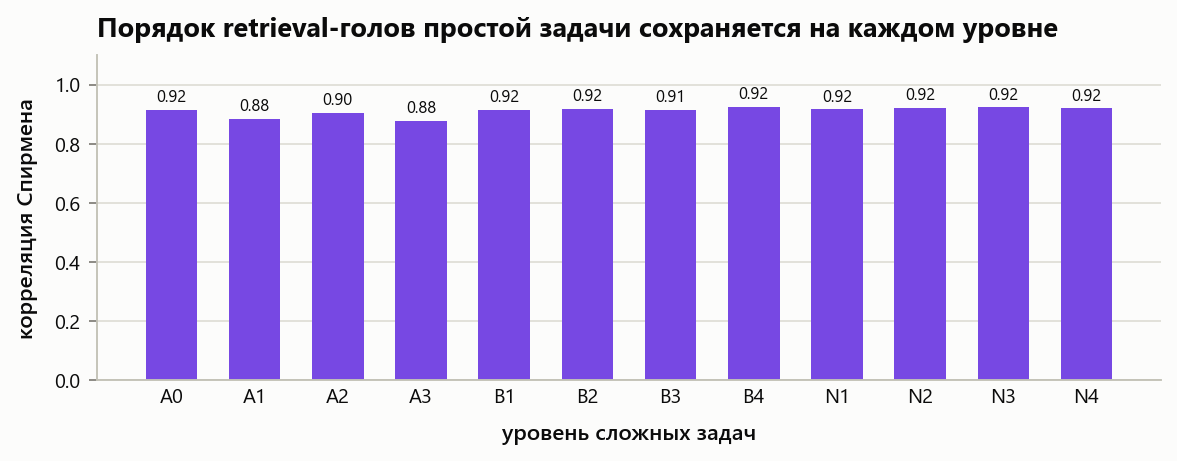

In [6]:
found = reference.ravel() > 0.1
rows = {}
for name, (heads, common) in {"A": (raw_a, common_a), "B": (raw_b, common_b), "N": (raw_n, common_n)}.items():
    for level, score in hard.level_scores(heads, "copy_recall", where=common).items():
        rows[level] = {"Спирмен с детекцией, 62 головы": data.spearman(score.ravel()[found], reference.ravel()[found]),
                       "общих голов в топ-20 с детекцией": data.top_overlap(score, reference, 20)}
kept = pd.DataFrame(rows).T
display(kept.round(3).T)

fig, ax = figure(1, 1, 2.6)
ax.bar(range(len(kept)), kept["Спирмен с детекцией, 62 головы"], width=0.62, color=VIOLET[6])
for x, value in enumerate(kept["Спирмен с детекцией, 62 головы"]):
    ax.annotate(f"{value:.2f}", (x, value), xytext=(0, 2), textcoords="offset points", ha="center", va="bottom", fontsize=t.font - 1.5)
ax.set_xticks(range(len(kept)), kept.index)
ax.tick_params(axis="x", length=0)
ax.set_ylim(0, 1.1)
plots.round_axis(ax, "y", 0, 1, 0.2)
ax.set_xlabel("уровень сложных задач")
ax.set_ylabel("корреляция Спирмена")
plots.titles(ax, "Порядок retrieval-голов простой задачи сохраняется на каждом уровне")
show(fig, "5b_ranking")